<img src="./src/LogoUTNNegro.png" align="right" width="150">

#### Teoría de los Circuitos 2

# Trabajo Semanal 10
#### Renzo Villani

**Parte A:**  Diseñe el cuadripolo A para que se comporte como:

- filtro pasa bajos Chevy de 3er. orden
- no disipativo
- normalizado en frecuencia e impedancia

respetando la siguiente topología:
<center><img src="./src/img1_TS10.png"  width="500"></center>

1. Obtenga la impedancia de entrada al cuadripolo A, cargado con un resistor de 1Ω a la salida.
2. Sintetice **A** como un cuadripolo escalera.
3. Simule el comportamiento de la red en LTspice graficando $S_{21}$ y $S_{21}$ en función de la frecuencia. (Ver explicación de Agustín Alba Chicar **1h 48m**)
4. Explique el comportamiento de A a partir de los valores de $S_{11}$ en las siguientes frecuencias:
- centro de la banda de paso
- frecuencia de corte
- transición y centro de la banda de detenida
5. Modifique el circuito para que la frecuencia de corte sea 2 π 10⁶ rad/s y la resistencia del generador sea 50Ω.

***Parte B:*** Trabajo de Investigación sobre NANO VNA ( Vector Network Analyzer )
1. Explique brevemente la función principal de un VNA y en que situación/es puede ser fundamental tenerlo como herramienta de medición.
2. Comparar respecto a un *DSO GW Insteak* características de: Ancho de Banda, Rango Dinámico e Impedancia de Entrada.
3. Además de las mediciones de los parametros, ***investigar*** si el equipo cuenta con alguna medición en el dominio del tiempo.

In [20]:
# Importo las librerías para trabajar de acá en adelante.

# Librerías externas NumPy, SciPy y Matplotlib
from scipy.signal import TransferFunction
from scipy import signal as sig
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

# Librería de TC2
from pytc2.sistemas_lineales import pzmap, GroupDelay, bodePlot, analyze_sys, tf2sos_analog

from pytc2.general import a_equal_b_latex_s, print_latex

In [21]:
order = 3

eps = 1

z,p,k = sig.cheb1ap(order, 3)
num21sq, den21sq = sig.zpk2tf(z,p,k)

T21 = TransferFunction(num, den)

print(T)

NameError: name 'num' is not defined

TransferFunctionContinuous(
array([1.  , 0.  , 0.75, 0.  ]),
array([1.        , 0.59607164, 0.9276507 , 0.25      ]),
dt: None
)


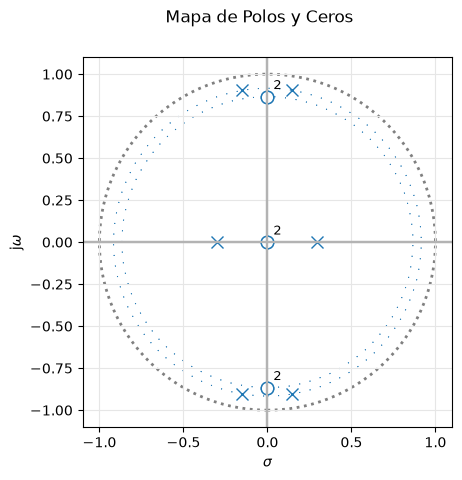

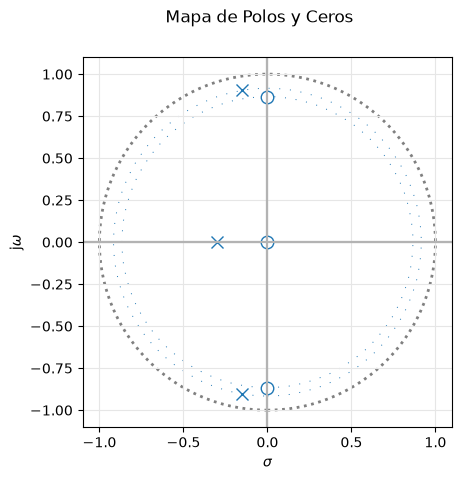

In [26]:
# Construyo |S11|²
numS11sq = np.array([-16, 0, -24, 0, -9, 0, 0])
denS11sq = np.array([-16, 0, -24, 0, -9, 0, 1])

TS11sq = TransferFunction(numS11sq , denS11sq)
pzmap(TS11sq)

# Construyo S11
Qroots = np.roots(denS11sq)
Qroots = Qroots[ np.real(Qroots) < 0 ]   # filtro los polos del semiplano derecho
denS11 = 4*np.poly(Qroots)
numS11 = np.array([4, 0, 3, 0])   # numerador hardcodeado para que los ceros sean simples

TS11 = TransferFunction(numS11 , denS11)
pzmap(TS11)
print(TS11)

TransferFunctionContinuous(
array([1.  , 0.  , 0.75, 0.  ]),
array([1.        , 0.59607164, 0.9276507 , 0.25      ]),
dt: None
)


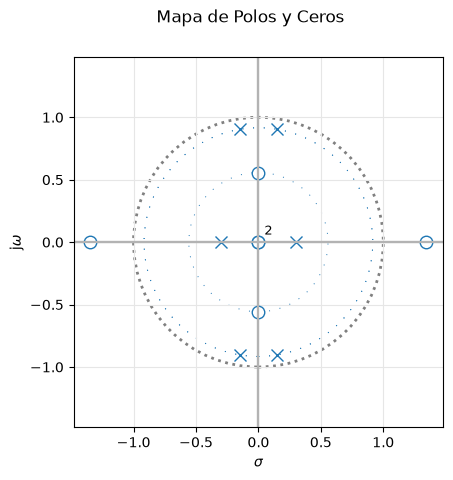

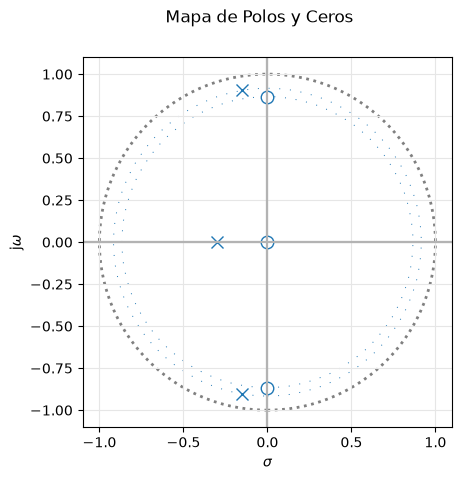

In [24]:
#TEST

# Construyo |S11|²
numS11sq = np.array([1, 0, -3/2, 0, -9/16, 0, 0])
denS11sq = np.array([1, 0, 3/2, 0, 9/16, 0, -1/16])

TS11sq = TransferFunction(numS11sq , denS11sq)
pzmap(TS11sq)

# Construyo S11
Qroots = np.roots(denS11sq)
Qroots = Qroots[ np.real(Qroots) < 0 ]   # filtro los polos del semiplano derecho
denS11 = 4*np.poly(Qroots)
numS11 = np.array([4, 0, 3, 0])   # numerador hardcodeado para que los ceros sean simples

TS11 = TransferFunction(numS11 , denS11)
pzmap(TS11)
print(TS11)